# 01 · Data reconstruction from the authorized COES workbook

**Purpose.** Rebuild the action-level table used in every later notebook, directly from the original workbook `Base_Observatorio_conflictos_2005-2024_v1.xlsx` (COES Observatorio de Conflictos, Harvard Dataverse, doi:10.7910/DVN/GKQXBR), and audit it.

**What this notebook does**
1. Verifies the SHA-256 of the workbook and records the digest of the frozen configuration (`../config/analysis_config_v2.json`).
2. Parses dates, media type, region, the broad conflict field P20a and the six tactic fields P29a–f, using the pilot rules, implemented in this notebook.
3. Applies the inherited filters and reports the sample flow by year: exact duplicates, invalid dates, actions without a valid tactic, and actions that repeat a valid code across fields.
4. Reports annual coverage (actions, media type, tactics per action, residual and invalid codes, saturated lists), tactic frequencies by year, and codebook consistency.
5. Checks that the pilot's published counts are reproduced.

**What it does not do.** It computes no co-occurrence between tactics. It does not use P14 (targets), attendance, participant identities or P19 (demands).

**Outputs.** `../data_local/actions.parquet` (action level, local only, never released) and aggregate tables in `../results/tables/`.

In [1]:
import os
for k in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS"]:
    os.environ.setdefault(k, "2")
import hashlib, json, re, unicodedata, sys, platform
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PROTEST_ROOT", Path.cwd())).expanduser().resolve()
if not (ROOT / "config" / "analysis_config_v2.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "config" / "analysis_config_v2.json").is_file():
    raise FileNotFoundError("Open this notebook from the repository root or its notebooks folder, or set PROTEST_ROOT.")
CFG_PATH = ROOT / "config" / "analysis_config_v2.json"
CFG = json.loads(CFG_PATH.read_text())
RAW = Path(os.environ.get("PROTEST_RAW", ROOT / "data_local" / "raw" / CFG["source"]["file"])).expanduser().resolve()
if not RAW.is_file():
    raise FileNotFoundError(f"Place {RAW.name} in data_local/raw/ or set PROTEST_RAW. Dataset: https://doi.org/10.7910/DVN/GKQXBR")
TAB = ROOT / "results" / "tables"; TAB.mkdir(parents=True, exist_ok=True)
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
LOCAL = ROOT / "data_local"; LOCAL.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

DIAG = ROOT / "results" / "diagnostics"
DIAG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

def display_figure(fig, name):
    """Show and export the same diagnostic figure."""
    display(fig)
    fig.savefig(DIAG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def display_and_save_table(df, name, index=False, float_format="%.4f"):
    """CSV plus a LaTeX rendering generated from the same DataFrame."""
    display(df)
    df.to_csv(TAB / f"{name}.csv", index=index)
    df.to_latex(TAB / f"{name}.tex", index=index, escape=True, float_format=lambda x: float_format % x)
    return df

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("platform", platform.platform())
print("config sha256", sha256(CFG_PATH))
print("Source workbook:", RAW.name)

python 3.12.14 | numpy 2.3.5 | pandas 2.2.3 | matplotlib 3.10.8
platform Linux-6.18.57-x86_64-with-glibc2.41
config sha256 579ee1b6a3eb8fe4f814e30d913dc545df49985387490195611ddb71420c76af
Source workbook: Base_Observatorio_conflictos_2005-2024_v1.xlsx


## 1. Verify the source and read it

The analysis stops if the workbook differs from the authorized version. The workbook is read in place and never copied.

In [2]:
raw_sha = sha256(RAW)
assert raw_sha == CFG["source"]["sha256"], f"SHA256 mismatch: {raw_sha}"
raw = pd.read_excel(RAW)
raw.columns = [str(c).strip().lower() for c in raw.columns]
print("raw sha256 OK:", raw_sha)
print("raw rows x columns:", raw.shape)

raw sha256 OK: 24b1870f1098d233674d6489a2df9ce2ba4e2fc74140015e01c555976e37075c
raw rows x columns: (38551, 90)


## 2. Tactic dictionary and codebook families

Labels follow the codebook annex (section 0.7.5, identical in the COES user manuals published in 2020 and 2022). The English short labels are ours. The codebook groups the 35 tactics into six lists; we keep those groups as *families*. Code 5 also covers the delivery of letters, petitions or lists of demands (manual definition), and code 17 includes *cacerolazos*.

In [3]:
TACTICS = {
 1: ("Marcha", "March"),
 2: ("Manifestación", "Static demonstration"),
 3: ("Acto con oradores", "Rally with speakers"),
 4: ("Caravana", "Caravan"),
 5: ("Recolección de firmas y/o dinero", "Petition or fund collection"),
 6: ("Desobediencia civil pacífica", "Peaceful civil disobedience"),
 7: ("Conferencia de prensa o declaración pública", "Press conference or statement"),
 8: ("Asamblea, discusión o debate abierto", "Assembly or open debate"),
 9: ("Rememoración u homenaje", "Commemoration"),
 10: ("Coros, cánticos, slogans o consignas", "Chants or slogans"),
 11: ("Boicots", "Boycott"),
 12: ("Rezos, sermones, símbolos religiosos", "Religious acts"),
 13: ("Vigilia", "Vigil"),
 14: ("Festejos colectivos con contenido político", "Political celebration"),
 15: ("Performance artística de los manifestantes", "Artistic performance (participants)"),
 16: ("Performance artística de artistas", "Artistic performance (artists)"),
 17: ("Actividades simbólicas no estrictamente artísticas", "Symbolic action"),
 18: ("Huelga o paro de actividades", "Strike or stoppage"),
 19: ("Toma u ocupación de edificios", "Building occupation"),
 20: ("Ocupación de predios y/o fundos", "Land occupation"),
 21: ("Ocupación de espacios públicos con carpas", "Encampment"),
 22: ("Cortes, barricadas o tomas de rutas", "Roadblock or barricade"),
 23: ("Interrupción de actividades de autoridades", "Interrupting authorities"),
 24: ("Funas", "Funa (public shaming)"),
 25: ("Huelga de hambre", "Hunger strike"),
 26: ("Actos peligrosos o autodestructivos", "Self-endangering act"),
 27: ("Incendio de vehículos, predios, edificios", "Arson"),
 28: ("Destrucción de propiedad pública o privada", "Property destruction"),
 29: ("Saqueo", "Looting"),
 30: ("Uso de artefactos explosivos o armas de fuego", "Explosives or firearms"),
 31: ("Agresiones entre manifestantes", "Fights among protesters"),
 32: ("Enfrentamientos con contra-manifestantes", "Clashes with counter-protesters"),
 33: ("Ataque a carabineros, guardias o FF.AA.", "Attack on police or security forces"),
 34: ("Ataque a transeúntes o terceros", "Attack on bystanders"),
 35: ("Toma de rehenes o secuestros", "Hostage taking"),
}
FAMILY_RANGES = {fam: tuple(r) for fam, r in CFG["tactic_families_codebook"].items()}
def family_of(code):
    for fam, (lo, hi) in FAMILY_RANGES.items():
        if lo <= code <= hi:
            return fam
FAMILY_LABEL = {"A_peaceful_1": "A Peaceful I", "B_peaceful_2": "B Peaceful II", "C_artistic": "C Artistic",
                "D_disruptive_nonviolent": "D Disruptive", "E_self_destructive": "E Self-destructive", "F_violent": "F Violent"}
dictionary = pd.DataFrame([{"code": c, "label_es": es, "label_en": en, "family": family_of(c),
                            "family_label": FAMILY_LABEL[family_of(c)]} for c, (es, en) in TACTICS.items()])
display_and_save_table(dictionary, "tactic_dictionary")
dictionary.groupby("family_label").code.agg(["min", "max", "count"])

,code,label_es,label_en,family,family_label
0,1,Marcha,March,A_peaceful_1,A Peaceful I
1,2,Manifestación,Static demonstration,A_peaceful_1,A Peaceful I
2,3,Acto con oradores,Rally with speakers,A_peaceful_1,A Peaceful I
3,4,Caravana,Caravan,A_peaceful_1,A Peaceful I
4,5,Recolección de firmas y/o dinero,Petition or fund collection,A_peaceful_1,A Peaceful I
5,6,Desobediencia civil pacífica,Peaceful civil disobedience,A_peaceful_1,A Peaceful I
6,7,Conferencia de prensa o declaración pública,Press conference or statement,B_peaceful_2,B Peaceful II
7,8,"Asamblea, discusión o debate abierto",Assembly or open debate,B_peaceful_2,B Peaceful II
8,9,Rememoración u homenaje,Commemoration,B_peaceful_2,B Peaceful II
9,10,"Coros, cánticos, slogans o consignas",Chants or slogans,B_peaceful_2,B Peaceful II


,min,max,count
family_label,,,
A Peaceful I,1,6,6
B Peaceful II,7,14,8
C Artistic,15,17,3
D Disruptive,18,24,7
E Self-destructive,25,26,2
F Violent,27,35,9


### Codebook consistency check

The definitions of the 35 tactic codes (annex 0.7.5 of the user manuals) are compared word for word between the two COES manuals published in 2020 and 2022 and available from the dataset record, after Unicode normalisation and removal of page headers and footers.

In [4]:

from pypdf import PdfReader
MAN = RAW.parent
def p29_annex(pdf):
    text = "\n".join(p.extract_text() or "" for p in PdfReader(pdf).pages)
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"Centro de Estudios de Conflicto y Cohesi.n Social - COES", " ", text)
    text = re.sub(r"P.gina \d+ de \d+", " ", text)
    # the heading first appears in the table of contents; the annex is its last occurrence
    start = text.rindex("Tácticas de protesta - P29"); end = text.index("99. Otra", start)
    return re.sub(r"\s+", " ", text[start:end]).strip()
manuals = {"2009-2019": MAN / "User_Manual_OC_Dataset_ 2009_2019.pdf", "2020": MAN / "Manual_Usuario_OCS_2020.pdf"}
if all(p.exists() for p in manuals.values()):
    annex = {k: p29_annex(v) for k, v in manuals.items()}
    same = annex["2009-2019"] == annex["2020"]
    codebook_check = {"p29_annex_identical": same, "characters": {k: len(v) for k, v in annex.items()},
                      "codes_found": {k: sorted(set(int(m) for m in re.findall(r"(?:^|\s)(\d{1,2})\. ", v) if 1 <= int(m) <= 35)) == list(range(1, 36)) for k, v in annex.items()}}
else:
    codebook_check = {"p29_annex_identical": None, "note": "manual PDFs not found next to the workbook"}
display(codebook_check)
(ROOT / "results" / "01_codebook_check.json").write_text(json.dumps(codebook_check, indent=1) + "\n")


{'p29_annex_identical': True,
 'characters': {'2009-2019': 4737, '2020': 4737},
 'codes_found': {'2009-2019': True, '2020': True}}

148

## 3. Parse fields

Rules inherited from the pilot:

* **Dates.** Start date from P5a (day), P5b (month), P5c (year; two-digit years + 2000). Rows without a valid start date are dropped.
* **Media.** `PB = 0` marks actions covered by newspapers (national or regional); `PB = 1` marks actions covered only by radio. COES recommends newspaper-only analyses for comparability because radio was not coded in every year; newspapers are the main sample and all media a sensitivity.
* **Region.** P6 harmonised to the 13 regions in force before 2007 (15→1, 14→10, 16→8). Conventional territorial blocks: regions 1–5, 6–8, 9–12, Metropolitan (13), and missing. These blocks are a convention, not official macro-regions.
* **Broad conflict field P20a.** Harmonised spellings mapped to the four fields of the manual (social reproduction, institutional, cultural, territorial), plus other, unclassified and missing. P20a is not a declared demand (P19 is not used).
* **Tactics P29a–f.** Valid codes 1–35; code 99 (“other”, free text) is a residual and never becomes a tactic; anything else non-empty is invalid. A tactic repeated in two fields cannot be represented as a set and the row is excluded, as in the pilot.

In [5]:
def norm(v):
    if pd.isna(v):
        return ""
    s = re.sub(r"\s+", " ", unicodedata.normalize("NFKC", str(v)).lower().strip())
    return "".join(c for c in unicodedata.normalize("NFKD", s) if not unicodedata.combining(c))

def numeric(s):
    return pd.to_numeric(s, errors="coerce").astype(float)

def parse_tactic(v):
    """Return (status, code) with status in valid / other / invalid / missing (pilot rule)."""
    s = norm(v)
    if s in ("", ".", "nan"):
        return "missing", 0
    try:
        z = float(s)
        if not np.isfinite(z) or int(z) != z:
            return "invalid", 0
        c = int(z)
    except (ValueError, OverflowError):
        return ("other", 0) if re.match(r"^99\s+\S", s) else ("invalid", 0)
    if c == 99:
        return "other", 0
    return ("valid", c) if 1 <= c <= 35 else ("invalid", 0)

assert parse_tactic(".") == ("missing", 0) and parse_tactic("99 texto") == ("other", 0)
assert parse_tactic(12.0) == ("valid", 12) and parse_tactic(36) == ("invalid", 0) and parse_tactic("1.5") == ("invalid", 0)

def broad_theme(s):
    """P20a harmonisation dictionary copied from the pilot (tactic_packages.py::broad_theme)."""
    s = norm(s)
    if s in ("", ".", "__missing__"):
        return "missing"
    if s in ["laboral/salarial", "laboral", "tierra", "tierras", "administracion de recursos economicos", "otros conflictos socioeconomicos"]:
        return "social_reproduction"
    if s in ["prestacion de servicios publicos", "gestion administrativa", "gestion adminisrativa", "gestion administativas",
             "gestion admnistrativa", "situacion/medidas legales", "cuestionamiento y/o reconocimiento autoridad",
             "cuestionamiento y/o reconocimiento de autoridad", "cuestionamiento y/o reconocimiento de la autoridad",
             "incumplimiento de convenios", "limites politico-administrativos"]:
        return "institutional"
    if s in ["ideologico-politico", "ideologico/politico", "seguridad ciudadana", "recursos naturales y medio ambiente",
             "recursos naturales y medioambiente", "valores/creencias/identidad", "valores, creencias e identidad", "derechos humanos"]:
        return "cultural"
    if s in ["recursos naturales y externalidades socioambientales", "uso de suelo, normativa e infraestructura",
             "uso de suelo, normativa en infraestructura", "politica y autonomia territorial", "desastres naturales",
             "identidad, memoria y patrimonio"]:
        return "territorial"
    if s == "otro":
        return "other"
    return "unclassified"

def block(region13):
    if pd.isna(region13):
        return "missing"
    r = int(region13)
    return "block_1_5" if r <= 5 else "block_6_8" if r <= 8 else "block_9_12" if r <= 12 else "region_13"

In [6]:
flow = {"raw_rows": len(raw)}
dup = raw.duplicated()
flow["exact_duplicates_removed"] = int(dup.sum())
df = raw.loc[~dup].copy()
df["source_row"] = df.index + 2          # Excel row number (header is row 1)
y = numeric(df["p5c"]); y = y.where(y >= 100, y + 2000)
df["date"] = pd.to_datetime({"year": y, "month": numeric(df["p5b"]), "day": numeric(df["p5a"])}, errors="coerce")
flow["invalid_start_date_removed"] = int(df.date.isna().sum())
df = df[df.date.notna()].copy()
df["year"] = df.date.dt.year.astype(int)
flow["rows_2005_2024_clean"] = len(df)
flow["newspaper_rows_2005_2024_clean"] = int(numeric(df.pb).eq(0).sum())
df = df[df.year.between(*CFG["sample"]["years"])].copy()
flow["rows_2008_2024"] = len(df)

df["pb"] = numeric(df.pb); df["pa"] = numeric(df.pa)
p6 = numeric(df.p6)
df["region13"] = p6.where(p6.between(1, 16) & p6.eq(p6.round())).replace({15: 1, 14: 10, 16: 8})
df["block"] = df.region13.map(block)
df["p20_broad"] = df.p20a.map(broad_theme)
df["month"] = df.date.dt.to_period("M").astype(str)
df["day"] = df.date.dt.strftime("%Y-%m-%d")

cols = [f"p29{c}" for c in "abcdef"]
parsed = [[parse_tactic(v) for v in row] for row in df[cols].itertuples(index=False, name=None)]
slots = np.array([[c for _, c in row] for row in parsed], dtype=np.int16)
status = np.array([[s for s, _ in row] for row in parsed])
df["n_valid_slots"] = (status == "valid").sum(1)
df["n_unique"] = [len(set(r[r > 0])) for r in slots]
df["n_other"] = (status == "other").sum(1)
df["n_invalid"] = (status == "invalid").sum(1)
df["n_nonmissing"] = (status != "missing").sum(1)
for j, c in enumerate("abcdef"):
    df[f"s{j+1}"] = slots[:, j]
print(json.dumps(flow, indent=1))
print("slot status counts 2008-2024:", pd.Series(status.ravel()).value_counts().to_dict())

{
 "raw_rows": 38551,
 "exact_duplicates_removed": 24,
 "invalid_start_date_removed": 3,
 "rows_2005_2024_clean": 38524,
 "newspaper_rows_2005_2024_clean": 31430,
 "rows_2008_2024": 34196
}
slot status counts 2008-2024: {'missing': 147717, 'valid': 56998, 'other': 460, 'invalid': 1}


## 4. Sample flow by year

Eligible actions have at least one valid tactic and no valid tactic repeated across fields. Residual (99) and invalid entries are kept as audit flags; they are never turned into tactics.

In [7]:
df["has_valid"] = df.n_unique > 0
df["repeated_code"] = df.n_valid_slots > df.n_unique
df["eligible"] = df.has_valid & ~df.repeated_code
def flow_table(d, label):
    f = pd.DataFrame({
        "year": d.year,
        "actions": 1,
        "no_valid_tactic": ~d.has_valid,
        "repeated_valid_code": d.has_valid & d.repeated_code,
        "eligible": d.eligible,
        "eligible_two_plus": d.eligible & (d.n_unique >= 2),
        "eligible_with_residual_99": d.eligible & (d.n_other > 0),
        "eligible_with_invalid": d.eligible & (d.n_invalid > 0),
        "eligible_six_fields": d.eligible & (d.n_nonmissing == 6),
    })
    t = f.groupby("year").sum().astype(int)
    t.loc["Total"] = t.sum()
    t.insert(0, "sample", label)
    return t.reset_index()
flow_news = flow_table(df[df.pb.eq(0)], "newspapers")
flow_all = flow_table(df, "all_media")
display_and_save_table(pd.concat([flow_news, flow_all]), "sample_flow_by_year")
flow_news

,year,sample,actions,no_valid_tactic,repeated_valid_code,eligible,eligible_two_plus,eligible_with_residual_99,eligible_with_invalid,eligible_six_fields
0,2008,newspapers,2023,8,0,2015,798,11,0,3
1,2009,newspapers,1421,2,0,1419,603,10,0,1
2,2010,newspapers,1152,0,0,1152,535,5,0,2
3,2011,newspapers,2247,0,1,2246,982,15,0,14
4,2012,newspapers,1467,0,0,1467,639,0,0,6
5,2013,newspapers,1832,0,0,1832,844,0,0,10
6,2014,newspapers,1795,0,0,1795,746,0,0,6
7,2015,newspapers,1264,0,0,1264,435,0,0,1
8,2016,newspapers,1587,0,0,1587,847,0,0,3
9,2017,newspapers,1078,1,0,1077,548,1,0,0


,year,sample,actions,no_valid_tactic,repeated_valid_code,eligible,eligible_two_plus,eligible_with_residual_99,eligible_with_invalid,eligible_six_fields
0,2008,newspapers,2023,8,0,2015,798,11,0,3
1,2009,newspapers,1421,2,0,1419,603,10,0,1
2,2010,newspapers,1152,0,0,1152,535,5,0,2
3,2011,newspapers,2247,0,1,2246,982,15,0,14
4,2012,newspapers,1467,0,0,1467,639,0,0,6
5,2013,newspapers,1832,0,0,1832,844,0,0,10
6,2014,newspapers,1795,0,0,1795,746,0,0,6
7,2015,newspapers,1264,0,0,1264,435,0,0,1
8,2016,newspapers,1587,0,0,1587,847,0,0,3
9,2017,newspapers,1078,1,0,1077,548,1,0,0


In [8]:
news = df[df.pb.eq(0) & df.eligible]
allm = df[df.eligible]
# Pilot published counts (pilot README, availability audit): reproduced exactly or the notebook stops.
checks = {
    "pilot clean actions 2005-2024 = 38524": flow["rows_2005_2024_clean"] == 38524,
    "pilot newspaper actions 2005-2024 = 31430": flow["newspaper_rows_2005_2024_clean"] == 31430,
    "pilot window 2008-2018 = 17258": int(news.year.between(2008, 2018).sum()) == 17258,
    "pilot window 2021-2024 = 4922": int(news.year.between(2021, 2024).sum()) == 4922,
    "availability 2019 = 3374": int((news.year == 2019).sum()) == 3374,
    "availability 2020 = 1934": int((news.year == 2020).sum()) == 1934,
    "main sample 2008-2024 = 27488": len(news) == 27488,
}
print(json.dumps(checks, indent=1))
assert all(checks.values())
print("main sample (newspapers):", len(news), "| all media:", len(allm))

{
 "pilot clean actions 2005-2024 = 38524": true,
 "pilot newspaper actions 2005-2024 = 31430": true,
 "pilot window 2008-2018 = 17258": true,
 "pilot window 2021-2024 = 4922": true,
 "availability 2019 = 3374": true,
 "availability 2020 = 1934": true,
 "main sample 2008-2024 = 27488": true
}
main sample (newspapers): 27488 | all media: 34118


## 5. Annual coverage and composition

Tactics per action (`k`) matter because a pair can only occur in actions with two or more tactics. The reference models hold each action's `k` fixed, so a change in `k` alone cannot create structure; it is still reported because it can reflect coding practice.

In [9]:
def coverage(d, label):
    g = d.groupby("year")
    t = pd.DataFrame({
        "actions": g.size(),
        "multi_tactic": g.n_unique.apply(lambda s: int((s >= 2).sum())),
        "share_multi": g.n_unique.apply(lambda s: (s >= 2).mean()),
        "mean_k": g.n_unique.mean(),
        "pairs_in_actions": g.n_unique.apply(lambda s: int((s * (s - 1) // 2).sum())),
        "share_regional_press": g.pa.apply(lambda s: s.eq(0).mean()),
        "share_national_press": g.pa.apply(lambda s: s.eq(1).mean()),
        "share_combined": g.pa.apply(lambda s: s.eq(3).mean()),
        "share_region_missing": g.block.apply(lambda s: s.eq("missing").mean()),
        "share_metropolitan": g.block.apply(lambda s: s.eq("region_13").mean()),
        "share_p20_missing": g.p20_broad.apply(lambda s: s.eq("missing").mean()),
        "months_with_actions": g.month.nunique(),
        "days_with_actions": g.day.nunique(),
    })
    t.insert(0, "sample", label)
    return t.reset_index()
cov = pd.concat([coverage(news, "newspapers"), coverage(allm, "all_media")])
display_and_save_table(cov, "annual_coverage")
kdist = pd.crosstab(news.year, news.n_unique.clip(upper=6))
kdist.columns = [f"k{c}" for c in kdist.columns]
display_and_save_table(kdist.reset_index(), "tactics_per_action_by_year")
cov[cov["sample"] == "newspapers"].round(3)

,year,sample,actions,multi_tactic,share_multi,mean_k,pairs_in_actions,share_regional_press,share_national_press,share_combined,share_region_missing,share_metropolitan,share_p20_missing,months_with_actions,days_with_actions
0,2008,newspapers,2015,798,0.396030,1.570720,1601,0.672953,0.156824,0.170223,0.014888,0.161290,0.022829,12,297
1,2009,newspapers,1419,603,0.424947,1.589852,1114,0.747710,0.124736,0.127555,0.000000,0.140240,0.022551,12,304
2,2010,newspapers,1152,535,0.464410,1.601562,889,0.741319,0.105035,0.153646,0.000000,0.163194,0.029514,12,295
3,2011,newspapers,2246,982,0.437222,1.671861,2283,0.716830,0.129118,0.154052,0.000000,0.161175,0.029831,12,325
4,2012,newspapers,1467,639,0.435583,1.610089,1257,0.620314,0.152011,0.227676,0.000000,0.167689,0.047035,12,323
5,2013,newspapers,1832,844,0.460699,1.644105,1651,0.685044,0.135917,0.179039,0.000000,0.135371,0.040393,12,329
6,2014,newspapers,1795,746,0.415599,1.551532,1322,0.758217,0.119777,0.122006,0.000000,0.113092,0.053482,12,324
7,2015,newspapers,1264,435,0.344146,1.477057,807,0.588608,0.223101,0.188291,0.000000,0.150316,0.054589,12,305
8,2016,newspapers,1587,847,0.533711,1.747322,1624,0.587272,0.148708,0.264020,0.000000,0.140517,0.039698,12,314
9,2017,newspapers,1077,548,0.508821,1.682451,963,0.512535,0.139276,0.348189,0.000000,0.212628,0.025070,12,298


,year,k1,k2,k3,k4,k5,k6
0,2008,1217,527,205,54,9,3
1,2009,816,404,171,22,5,1
2,2010,617,405,110,14,4,2
3,2011,1264,630,235,73,30,14
4,2012,828,457,134,28,14,6
5,2013,988,602,179,42,11,10
6,2014,1049,564,140,28,8,6
7,2015,829,297,113,21,3,1
8,2016,740,588,195,51,10,3
9,2017,529,395,126,20,7,0


,year,sample,actions,multi_tactic,share_multi,mean_k,pairs_in_actions,share_regional_press,share_national_press,share_combined,share_region_missing,share_metropolitan,share_p20_missing,months_with_actions,days_with_actions
0,2008,newspapers,2015,798,0.396,1.571,1601,0.673,0.157,0.170,0.015,0.161,0.023,12,297
1,2009,newspapers,1419,603,0.425,1.590,1114,0.748,0.125,0.128,0.000,0.140,0.023,12,304
2,2010,newspapers,1152,535,0.464,1.602,889,0.741,0.105,0.154,0.000,0.163,0.030,12,295
3,2011,newspapers,2246,982,0.437,1.672,2283,0.717,0.129,0.154,0.000,0.161,0.030,12,325
4,2012,newspapers,1467,639,0.436,1.610,1257,0.620,0.152,0.228,0.000,0.168,0.047,12,323
5,2013,newspapers,1832,844,0.461,1.644,1651,0.685,0.136,0.179,0.000,0.135,0.040,12,329
6,2014,newspapers,1795,746,0.416,1.552,1322,0.758,0.120,0.122,0.000,0.113,0.053,12,324
7,2015,newspapers,1264,435,0.344,1.477,807,0.589,0.223,0.188,0.000,0.150,0.055,12,305
8,2016,newspapers,1587,847,0.534,1.747,1624,0.587,0.149,0.264,0.000,0.141,0.040,12,314
9,2017,newspapers,1077,548,0.509,1.682,963,0.513,0.139,0.348,0.000,0.213,0.025,12,298


In [10]:
p20 = pd.crosstab(news.year, news.p20_broad, normalize="index").round(3)
display_and_save_table(p20.reset_index(), "p20_broad_by_year")
blocks = pd.crosstab(news.year, news.block, normalize="index").round(3)
display_and_save_table(blocks.reset_index(), "territorial_block_by_year")
p20map = df.assign(p20a_norm=df.p20a.map(norm)).groupby(["p20a_norm", "p20_broad"]).size().rename("actions").reset_index()
display_and_save_table(p20map, "p20_mapping")
display(p20)
blocks

p20_broad,year,cultural,institutional,missing,other,social_reproduction,territorial
0,2008,0.071,0.267,0.023,0.000,0.573,0.066
1,2009,0.127,0.115,0.023,0.006,0.665,0.065
2,2010,0.105,0.195,0.030,0.014,0.558,0.098
3,2011,0.092,0.098,0.030,0.015,0.710,0.055
4,2012,0.098,0.247,0.047,0.016,0.513,0.079
5,2013,0.116,0.184,0.040,0.010,0.578,0.072
6,2014,0.100,0.212,0.053,0.013,0.542,0.079
7,2015,0.152,0.252,0.055,0.022,0.424,0.096
8,2016,0.112,0.234,0.040,0.017,0.534,0.064
9,2017,0.150,0.284,0.025,0.014,0.430,0.097


block,year,block_1_5,block_6_8,block_9_12,missing,region_13
0,2008,0.348,0.170,0.306,0.015,0.161
1,2009,0.336,0.139,0.385,0.000,0.140
2,2010,0.444,0.098,0.294,0.000,0.163
3,2011,0.398,0.127,0.313,0.000,0.161
4,2012,0.344,0.127,0.361,0.000,0.168
5,2013,0.454,0.126,0.285,0.000,0.135
6,2014,0.423,0.150,0.314,0.000,0.113
7,2015,0.396,0.065,0.389,0.000,0.150
8,2016,0.369,0.112,0.379,0.000,0.141
9,2017,0.383,0.098,0.306,0.000,0.213


,p20a_norm,p20_broad,actions
0,.,missing,2098
1,administracion de recursos economicos,social_reproduction,129
2,cuestionamiento y/o reconocimiento de autoridad,institutional,254
3,derechos humanos,cultural,2029
4,desastres naturales,territorial,135
5,gestion administrativa,institutional,2135
6,"identidad, memoria y patrimonio",territorial,643
7,ideologico-politico,cultural,162
8,incumplimiento de convenios,institutional,241
9,laboral/salarial,social_reproduction,10069


p20_broad,cultural,institutional,missing,other,social_reproduction,territorial
year,,,,,,
2008,0.071,0.267,0.023,0.000,0.573,0.066
2009,0.127,0.115,0.023,0.006,0.665,0.065
2010,0.105,0.195,0.030,0.014,0.558,0.098
2011,0.092,0.098,0.030,0.015,0.710,0.055
2012,0.098,0.247,0.047,0.016,0.513,0.079
2013,0.116,0.184,0.040,0.010,0.578,0.072
2014,0.100,0.212,0.053,0.013,0.542,0.079
2015,0.152,0.252,0.055,0.022,0.424,0.096
2016,0.112,0.234,0.040,0.017,0.534,0.064


block,block_1_5,block_6_8,block_9_12,missing,region_13
year,,,,,
2008,0.348,0.170,0.306,0.015,0.161
2009,0.336,0.139,0.385,0.000,0.140
2010,0.444,0.098,0.294,0.000,0.163
2011,0.398,0.127,0.313,0.000,0.161
2012,0.344,0.127,0.361,0.000,0.168
2013,0.454,0.126,0.285,0.000,0.135
2014,0.423,0.150,0.314,0.000,0.113
2015,0.396,0.065,0.389,0.000,0.150
2016,0.369,0.112,0.379,0.000,0.141


## 6. Tactic frequencies by year (the *frequency* side of repertoire change)

Counts are numbers of eligible newspaper actions that include each tactic. These marginals are what the reference models hold fixed (by month in N1, by year × context × field position in N2).

In [11]:
codes = np.arange(1, 36)
S = news[[f"s{j}" for j in range(1, 7)]].to_numpy()
inc = np.zeros((len(news), 35), dtype=np.int8)
for j in range(6):
    m = S[:, j] > 0
    inc[np.where(m)[0], S[m, j] - 1] = 1
assert inc.sum() == news.n_unique.sum()
marg = pd.DataFrame(inc, columns=codes).groupby(news.year.to_numpy()).sum()
display_and_save_table(marg.reset_index().rename(columns={"index": "year"}), "tactic_counts_by_year")
share = marg.div(news.groupby("year").size(), axis=0)
display_and_save_table(share.reset_index().rename(columns={"index": "year"}), "tactic_share_by_year", float_format="%.5f")
print("codes never used in a year (count = 0):")
print({int(c): [int(y) for y in marg.index[marg[c] == 0]] for c in codes if (marg[c] == 0).any()})
marg

codes never used in a year (count = 0):
{6: [2008, 2009, 2015, 2018, 2023, 2024], 7: [2009, 2010, 2012, 2023, 2024], 8: [2009, 2024], 11: [2008, 2009, 2010, 2011, 2024], 12: [2018, 2024], 14: [2009, 2012, 2014, 2015], 20: [2024], 21: [2015], 24: [2024], 29: [2010, 2018], 31: [2012, 2013, 2015, 2018], 32: [2023], 34: [2024], 35: [2008, 2009, 2010, 2011, 2012, 2013, 2015, 2016, 2017, 2019, 2020, 2022, 2024]}


,year,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
0,2008,396,445,51,24,69,0,1,6,31,341,0,5,11,1,13,13,50,684,335,7,1,282,28,10,41,14,22,74,7,38,6,4,137,18,0
1,2009,310,296,55,18,46,0,0,0,55,270,0,3,14,0,3,9,38,470,92,44,5,228,21,16,35,26,28,43,1,38,3,2,80,7,0
2,2010,297,319,46,5,37,2,0,5,28,324,0,2,4,1,9,11,32,281,64,33,4,136,13,7,49,14,23,16,0,22,2,1,51,7,0
3,2011,654,394,78,39,67,3,1,3,25,451,0,5,16,1,23,20,224,371,406,12,9,409,33,36,36,21,46,97,12,35,3,2,214,9,0
4,2012,378,250,64,15,49,1,0,5,27,198,3,1,13,0,30,12,62,193,184,21,2,412,11,28,14,19,73,59,10,66,0,3,146,13,0
5,2013,453,324,45,17,62,2,4,2,26,346,7,6,14,1,42,21,85,541,169,9,1,451,6,21,17,15,65,62,4,56,0,2,118,18,0
6,2014,474,279,56,40,46,1,7,4,19,316,4,5,19,0,32,15,98,501,123,21,4,342,25,26,20,9,77,41,1,68,3,1,89,18,1
7,2015,362,262,22,13,15,0,5,4,7,186,2,2,8,0,14,7,102,268,85,13,0,239,9,16,15,6,85,11,3,35,0,12,46,13,0
8,2016,473,439,38,41,14,2,21,4,6,329,10,4,8,3,65,18,62,361,146,8,8,312,24,32,22,13,132,39,5,31,4,4,73,22,0
9,2017,280,244,26,29,44,2,1,1,12,327,1,6,10,1,24,7,54,236,90,5,2,174,12,17,13,11,66,29,3,22,2,5,42,14,0


,year,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
0,2008,0.196526,0.220844,0.025310,0.011911,0.034243,0.000000,0.000496,0.002978,0.015385,0.169231,0.000000,0.002481,0.005459,0.000496,0.006452,0.006452,0.024814,0.339454,0.166253,0.003474,0.000496,0.139950,0.013896,0.004963,0.020347,0.006948,0.010918,0.036725,0.003474,0.018859,0.002978,0.001985,0.067990,0.008933,0.000000
1,2009,0.218464,0.208598,0.038760,0.012685,0.032417,0.000000,0.000000,0.000000,0.038760,0.190275,0.000000,0.002114,0.009866,0.000000,0.002114,0.006342,0.026779,0.331219,0.064834,0.031008,0.003524,0.160677,0.014799,0.011276,0.024665,0.018323,0.019732,0.030303,0.000705,0.026779,0.002114,0.001409,0.056378,0.004933,0.000000
2,2010,0.257812,0.276910,0.039931,0.004340,0.032118,0.001736,0.000000,0.004340,0.024306,0.281250,0.000000,0.001736,0.003472,0.000868,0.007812,0.009549,0.027778,0.243924,0.055556,0.028646,0.003472,0.118056,0.011285,0.006076,0.042535,0.012153,0.019965,0.013889,0.000000,0.019097,0.001736,0.000868,0.044271,0.006076,0.000000
3,2011,0.291184,0.175423,0.034728,0.017364,0.029831,0.001336,0.000445,0.001336,0.011131,0.200801,0.000000,0.002226,0.007124,0.000445,0.010240,0.008905,0.099733,0.165183,0.180766,0.005343,0.004007,0.182102,0.014693,0.016028,0.016028,0.009350,0.020481,0.043188,0.005343,0.015583,0.001336,0.000890,0.095280,0.004007,0.000000
4,2012,0.257669,0.170416,0.043626,0.010225,0.033401,0.000682,0.000000,0.003408,0.018405,0.134969,0.002045,0.000682,0.008862,0.000000,0.020450,0.008180,0.042263,0.131561,0.125426,0.014315,0.001363,0.280845,0.007498,0.019087,0.009543,0.012952,0.049761,0.040218,0.006817,0.044990,0.000000,0.002045,0.099523,0.008862,0.000000
5,2013,0.247271,0.176856,0.024563,0.009279,0.033843,0.001092,0.002183,0.001092,0.014192,0.188865,0.003821,0.003275,0.007642,0.000546,0.022926,0.011463,0.046397,0.295306,0.092249,0.004913,0.000546,0.246179,0.003275,0.011463,0.009279,0.008188,0.035480,0.033843,0.002183,0.030568,0.000000,0.001092,0.064410,0.009825,0.000000
6,2014,0.264067,0.155432,0.031198,0.022284,0.025627,0.000557,0.003900,0.002228,0.010585,0.176045,0.002228,0.002786,0.010585,0.000000,0.017827,0.008357,0.054596,0.279109,0.068524,0.011699,0.002228,0.190529,0.013928,0.014485,0.011142,0.005014,0.042897,0.022841,0.000557,0.037883,0.001671,0.000557,0.049582,0.010028,0.000557
7,2015,0.286392,0.207278,0.017405,0.010285,0.011867,0.000000,0.003956,0.003165,0.005538,0.147152,0.001582,0.001582,0.006329,0.000000,0.011076,0.005538,0.080696,0.212025,0.067247,0.010285,0.000000,0.189082,0.007120,0.012658,0.011867,0.004747,0.067247,0.008703,0.002373,0.027690,0.000000,0.009494,0.036392,0.010285,0.000000
8,2016,0.298047,0.276623,0.023945,0.025835,0.008822,0.001260,0.013233,0.002520,0.003781,0.207309,0.006301,0.002520,0.005041,0.001890,0.040958,0.011342,0.039067,0.227473,0.091997,0.005041,0.005041,0.196597,0.015123,0.020164,0.013863,0.008192,0.083176,0.024575,0.003151,0.019534,0.002520,0.002520,0.045999,0.013863,0.000000
9,2017,0.259981,0.226555,0.024141,0.026927,0.040854,0.001857,0.000929,0.000929,0.011142,0.303621,0.000929,0.005571,0.009285,0.000929,0.022284,0.006500,0.050139,0.219127,0.083565,0.004643,0.001857,0.161560,0.011142,0.015785,0.012071,0.010214,0.061281,0.026927,0.002786,0.020427,0.001857,0.004643,0.038997,0.012999,0.000000


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35
2008,396,445,51,24,69,0,1,6,31,341,0,5,11,1,13,13,50,684,335,7,1,282,28,10,41,14,22,74,7,38,6,4,137,18,0
2009,310,296,55,18,46,0,0,0,55,270,0,3,14,0,3,9,38,470,92,44,5,228,21,16,35,26,28,43,1,38,3,2,80,7,0
2010,297,319,46,5,37,2,0,5,28,324,0,2,4,1,9,11,32,281,64,33,4,136,13,7,49,14,23,16,0,22,2,1,51,7,0
2011,654,394,78,39,67,3,1,3,25,451,0,5,16,1,23,20,224,371,406,12,9,409,33,36,36,21,46,97,12,35,3,2,214,9,0
2012,378,250,64,15,49,1,0,5,27,198,3,1,13,0,30,12,62,193,184,21,2,412,11,28,14,19,73,59,10,66,0,3,146,13,0
2013,453,324,45,17,62,2,4,2,26,346,7,6,14,1,42,21,85,541,169,9,1,451,6,21,17,15,65,62,4,56,0,2,118,18,0
2014,474,279,56,40,46,1,7,4,19,316,4,5,19,0,32,15,98,501,123,21,4,342,25,26,20,9,77,41,1,68,3,1,89,18,1
2015,362,262,22,13,15,0,5,4,7,186,2,2,8,0,14,7,102,268,85,13,0,239,9,16,15,6,85,11,3,35,0,12,46,13,0
2016,473,439,38,41,14,2,21,4,6,329,10,4,8,3,65,18,62,361,146,8,8,312,24,32,22,13,132,39,5,31,4,4,73,22,0
2017,280,244,26,29,44,2,1,1,12,327,1,6,10,1,24,7,54,236,90,5,2,174,12,17,13,11,66,29,3,22,2,5,42,14,0


,year,tvd_year_vs_rest
0,2008,0.194662
1,2009,0.167828
2,2010,0.194662
3,2011,0.184114
4,2012,0.178235
5,2013,0.142901
6,2014,0.144939
7,2015,0.140974
8,2016,0.129952
9,2017,0.113350


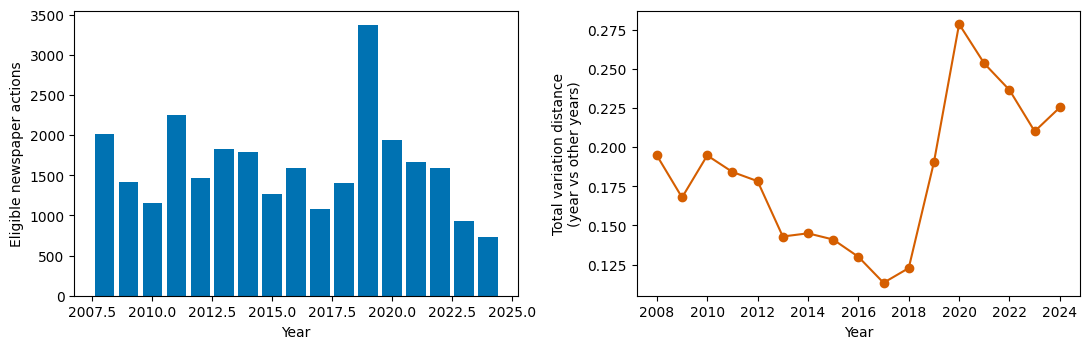

{2008: 0.195,
 2009: 0.168,
 2010: 0.195,
 2011: 0.184,
 2012: 0.178,
 2013: 0.143,
 2014: 0.145,
 2015: 0.141,
 2016: 0.13,
 2017: 0.113,
 2018: 0.123,
 2019: 0.19,
 2020: 0.279,
 2021: 0.253,
 2022: 0.236,
 2023: 0.21,
 2024: 0.225}

In [12]:
# Frequency change in one number per year: total variation distance between the year's tactic profile
# (share of tactic mentions) and the profile of all other years pooled.
mentions = marg.div(marg.sum(1), axis=0)
tvd = {}
for yr in marg.index:
    rest = marg.drop(index=yr).sum()
    tvd[yr] = 0.5 * np.abs(mentions.loc[yr] - rest / rest.sum()).sum()
tvd = pd.Series(tvd, name="tvd_year_vs_rest")
display_and_save_table(tvd.rename_axis("year").reset_index(), "tactic_profile_tvd_year_vs_rest")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(marg.index, news.groupby("year").size(), color="#0072B2")
ax[0].set_ylabel("Eligible newspaper actions"); ax[0].set_xlabel("Year")
ax[1].plot(tvd.index, tvd.values, "o-", color="#D55E00")
ax[1].set_ylabel("Total variation distance\n(year vs other years)"); ax[1].set_xlabel("Year")
fig.tight_layout()
display_figure(fig, "tactic_frequency_by_year")
tvd.round(3).to_dict()

## 7. Field positions and order (audit only)

The manual does not define P29a as the main tactic or the fields as a sequence. We report how often valid codes are compacted into the first fields and how often multi-tactic lists are in ascending numeric order; N2 conditions on field position and N2_order additionally preserves the ascending-order status.

In [13]:
def ascending(row):
    v = row[row > 0]
    return bool(np.all(v[1:] > v[:-1]))
occupied = S > 0
compact = np.array([list(o) == sorted(o, reverse=True) for o in occupied])
multi = news.n_unique.to_numpy() >= 2
asc = np.array([ascending(r) for r in S])
order_audit = pd.DataFrame({"year": news.year.to_numpy(), "compact": compact, "ascending": asc, "multi": multi})
order_tab = pd.DataFrame({
    "share_compact_fields": order_audit.groupby("year").compact.mean(),
    "share_ascending_among_multi": order_audit[order_audit.multi].groupby("year").ascending.mean()}).reset_index()
display_and_save_table(order_tab, "field_order_audit_by_year")
order_tab.round(3)

,year,share_compact_fields,share_ascending_among_multi
0,2008,0.999504,0.598997
1,2009,1.000000,0.557214
2,2010,1.000000,0.691589
3,2011,1.000000,0.659878
4,2012,1.000000,0.691706
5,2013,1.000000,0.620853
6,2014,1.000000,0.595174
7,2015,0.982595,0.586207
8,2016,0.999370,0.602125
9,2017,1.000000,0.580292


,year,share_compact_fields,share_ascending_among_multi
0,2008,1.000,0.599
1,2009,1.000,0.557
2,2010,1.000,0.692
3,2011,1.000,0.660
4,2012,1.000,0.692
5,2013,1.000,0.621
6,2014,1.000,0.595
7,2015,0.983,0.586
8,2016,0.999,0.602
9,2017,1.000,0.580


## 8. Save the local action-level table

`data_local/` is excluded from every redistributable package: it holds action-level rows derived from the COES workbook.

In [14]:
keep = ["source_row", "date", "year", "month", "day", "pb", "pa", "region13", "block", "p20_broad",
        "s1", "s2", "s3", "s4", "s5", "s6", "n_unique", "n_valid_slots", "n_other", "n_invalid", "n_nonmissing", "eligible"]
out = df.loc[df.eligible, keep].sort_values(["date", "source_row"]).reset_index(drop=True)
out["action_id"] = np.arange(len(out))

# This event-level cache stays local. Only the aggregate audit is displayed.
display(pd.Series({"Eligible actions": len(out), "Selected fields": len(out.columns)}, name="Local cache"))
out.to_parquet(LOCAL / "actions.parquet", index=False)
meta = {"raw_sha256": raw_sha, "config_sha256": sha256(CFG_PATH), "flow": flow,
        "eligible_all_media": int(len(out)), "eligible_newspapers": int(out.pb.eq(0).sum()),
        "actions_parquet_sha256": sha256(LOCAL / "actions.parquet")}
display(meta)
(ROOT / "results" / "01_reconstruction_meta.json").write_text(json.dumps(meta, indent=1) + "\n")


Eligible actions    34118
Selected fields        23
Name: Local cache, dtype: int64

{'raw_sha256': '24b1870f1098d233674d6489a2df9ce2ba4e2fc74140015e01c555976e37075c',
 'config_sha256': '579ee1b6a3eb8fe4f814e30d913dc545df49985387490195611ddb71420c76af',
 'flow': {'raw_rows': 38551,
  'exact_duplicates_removed': 24,
  'invalid_start_date_removed': 3,
  'rows_2005_2024_clean': 38524,
  'newspaper_rows_2005_2024_clean': 31430,
  'rows_2008_2024': 34196},
 'eligible_all_media': 34118,
 'eligible_newspapers': 27488,
 'actions_parquet_sha256': '4fcf79ded1d7446d574c7c796131354fa02eb41c0c72c5594373e83945de3dac'}

535